# Visual FID procedure with CIFAR-10 and Flowers102

**Audience.** This notebook is for researchers. It shows the exact input to the repository FID implementation.

**Prerequisites.** Install the `image` and `evaluation` dependencies. Put the CIFAR-10 and Flowers102 files in `data/`. The notebook sets `download=False`. Thus, it does not download dataset files. Before the first FID calculation, make sure that the torch-fidelity Inception weights are available.

**Goals.** After this procedure, you can:

- Identify the exact image tensors that FID uses.
- Use the repository `compute_image_fid` adapter.
- Confirm the identical-input control.
- Interpret same-dataset and cross-dataset results.
- Keep small-sample results separate from paper results.


## Outline

1. Set the evaluation protocol.
2. Load deterministic, disjoint dataset subsets.
3. Show the exact FID inputs.
4. Calculate three FID values.
5. Interpret the results and limits.
6. Do an optional exercise.


In [1]:
# Purpose: Set one reproducible FID protocol and find the local data.
# These standard-library tools report versions, paths, and elapsed time.
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

# Matplotlib shows inputs and results. Torch and Torchvision supply tensors and datasets.
import matplotlib.pyplot as plt
import torch
from torchvision import datasets, transforms

# Use the repository FID adapter. Do not use a second FID implementation.
from mem_param_src.metrics.image import compute_image_fid


def find_repo_root(start):
    # Examine this folder and each parent folder.
    for candidate in (start, *start.parents):
        # The pyproject.toml file identifies the repository root.
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("The repository root is not available.")


# Keep all paths relative to the repository. Do not put a user home path in the code.
REPO_ROOT = find_repo_root(Path.cwd().resolve())
DATA_ROOT = REPO_ROOT / "data"
SEED = 23  # Use the same subset indices in each run.
N_FID = 32  # Use a small sample for this test. Do not use it for paper results.
FID_BATCH_SIZE = 16  # Control feature-extraction memory. This value does not change FID.
IMAGE_SIZE = 32  # Use the same image size for CIFAR and Flowers.
DEVICE = "cpu"  # Use the verified device. Avoid device-specific GPU effects.

torch.manual_seed(SEED)  # Control random values from later Torch operations.
# Stop if the local dataset directory does not exist.
assert DATA_ROOT.is_dir(), f"The local data directory does not exist: {DATA_ROOT}"

# Show the complete run protocol with the FID results.
print(f"repository: {REPO_ROOT}")
print(f"data root:  {DATA_ROOT}")
print(f"torch:      {torch.__version__}")
print(f"torchvision:{version('torchvision')}")
print(f"torch-fidelity: {version('torch-fidelity')}")
print(f"protocol: N={N_FID}, image_size={IMAGE_SIZE}, device={DEVICE}")


repository: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean
data root:  /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean/data
torch:      2.13.0
torchvision:0.28.0
torch-fidelity: 0.4.0
protocol: N=32, image_size=32, device=cpu


## 1. What FID measures

FID uses the same Inception-v3 feature extractor for both image sets. It fits one Gaussian distribution to each feature set. It compares the means and covariance matrices with this equation:

$$
\operatorname{FID}(A,B)=\lVert\mu_A-\mu_B\rVert_2^2 + \operatorname{Tr}\left(\Sigma_A+\Sigma_B-2(\Sigma_A\Sigma_B)^{1/2}\right).
$$

A lower FID value shows a smaller distance **in this fixed feature space**. FID cannot identify copies of training examples. Thus, FID is not a memorization metric. This notebook uses only 32 images in each set. This small sample keeps the run time short. Do not use these values as dataset-level estimates.


## 2. Load the local datasets

Resize each image to 32 × 32. Convert each image to a float tensor in `[0, 1]`. Do not use data augmentation. The `download=False` value confirms that the notebook uses the local dataset files.


In [2]:
# Purpose: Load three local dataset splits with one fixed image transform.
# Use the same spatial and numeric preprocess for each FID comparison.
fid_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),  # Set one spatial resolution.
        transforms.ToTensor(),  # Convert PIL data to float [C, H, W] data in [0, 1].
    ]
)

# The download=False value makes the code use the local dataset files.
cifar_train = datasets.CIFAR10(
    DATA_ROOT, train=True, transform=fid_transform, download=False
)
# The official test split and train split do not share images.
cifar_test = datasets.CIFAR10(
    DATA_ROOT, train=False, transform=fid_transform, download=False
)
# Flowers validation gives a different reference distribution.
flowers_val = datasets.Flowers102(
    DATA_ROOT, split="val", transform=fid_transform, download=False
)

# Confirm the official split sizes before you select examples.
print(f"CIFAR-10 train: {len(cifar_train):,}")
print(f"CIFAR-10 test:  {len(cifar_test):,}")
print(f"Flowers102 val: {len(flowers_val):,}")


CIFAR-10 train: 50,000
CIFAR-10 test:  10,000
Flowers102 val: 1,020


## 3. Freeze the exact subsets

Use one seeded permutation to select the exact indices. The notebook keeps two disjoint CIFAR-10 training subsets. These subsets support the optional exercise. Use the same number of images in each main comparison. This rule removes sample-count asymmetry.


In [3]:
# Purpose: Set equal deterministic subsets and keep their labels.
def collect_indices(dataset, indices):
    # Get the exact indexed examples. The transform occurs during this operation.
    examples = [dataset[index] for index in indices]
    # Stack [C, H, W] images into one [N, C, H, W] FID batch.
    images = torch.stack([image for image, _ in examples])
    labels = torch.tensor([label for _, label in examples])  # Use labels only in figures.
    return images, labels


# A local generator gives the same subset indices in each run.
generator = torch.Generator().manual_seed(SEED)
# One permutation puts A and B in separate index ranges.
cifar_train_order = torch.randperm(len(cifar_train), generator=generator)
cifar_a_indices = cifar_train_order[:N_FID].tolist()  # Use this sample in the main test.
cifar_b_indices = cifar_train_order[N_FID : 2 * N_FID].tolist()  # Keep this sample for the exercise.
# Select equal comparison subsets from the other official datasets.
cifar_test_indices = torch.randperm(
    len(cifar_test), generator=generator
)[:N_FID].tolist()
flowers_val_indices = torch.randperm(
    len(flowers_val), generator=generator
)[:N_FID].tolist()

# Convert each index list to the exact tensor that FID uses.
cifar_a, cifar_a_labels = collect_indices(cifar_train, cifar_a_indices)
cifar_b, cifar_b_labels = collect_indices(cifar_train, cifar_b_indices)
cifar_test_batch, cifar_test_labels = collect_indices(
    cifar_test, cifar_test_indices
)
flowers_val_batch, flowers_val_labels = collect_indices(
    flowers_val, flowers_val_indices
)

# Confirm that the two exercise subsets do not share indices.
assert set(cifar_a_indices).isdisjoint(cifar_b_indices)
print(f"CIFAR train A first indices: {cifar_a_indices[:5]}")
print(f"CIFAR train B first indices: {cifar_b_indices[:5]}")
print("CIFAR train A/B overlap: 0")


CIFAR train A first indices: [27491, 7723, 36110, 17173, 37662]
CIFAR train B first indices: [24803, 4487, 37087, 21956, 29971]
CIFAR train A/B overlap: 0


In [4]:
# Purpose: Verify the tensor requirements before FID hides input errors.
# Give each tensor a clear name. Apply the same tests to each tensor.
batches = {
    "CIFAR train A": cifar_a,
    "CIFAR test": cifar_test_batch,
    "Flowers val": flowers_val_batch,
}

for name, images in batches.items():
    # Confirm that FID receives equal RGB batches with the 32 × 32 protocol.
    assert images.shape == (N_FID, 3, IMAGE_SIZE, IMAGE_SIZE)
    assert images.dtype == torch.float32  # Confirm the documented ToTensor output type.
    # The image_range='0_1' value is valid only for values in this range.
    assert 0.0 <= float(images.min()) <= float(images.max()) <= 1.0
    # Show the shape and the measured value range.
    print(
        f"{name:14s} shape={tuple(images.shape)}, "
        f"range=[{float(images.min()):.3f}, {float(images.max()):.3f}]"
    )


CIFAR train A  shape=(32, 3, 32, 32), range=[0.000, 1.000]
CIFAR test     shape=(32, 3, 32, 32), range=[0.000, 1.000]
Flowers val    shape=(32, 3, 32, 32), range=[0.000, 1.000]


## 4. Examine the FID inputs

The figure shows the first eight images from each exact subset. It does not summarize the full datasets. Use the figure to find errors in split, channel order, value range, image size, or image content.


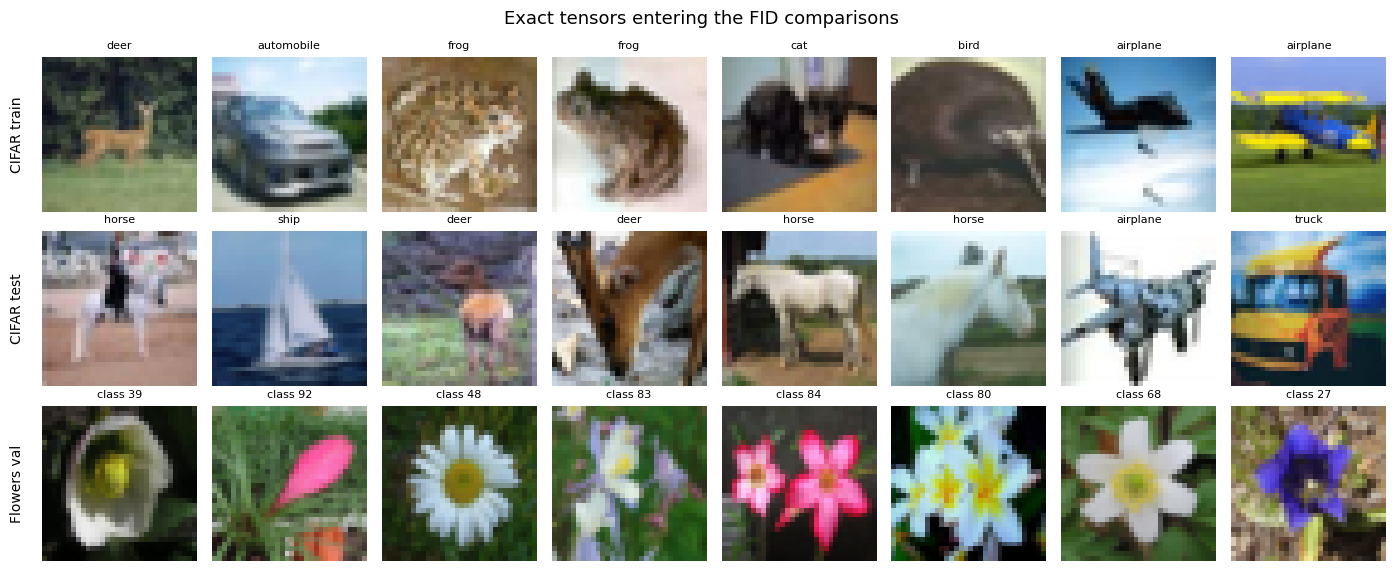

In [5]:
# Purpose: Show the exact images that the three FID comparisons use.
def show_image_row(axes, images, labels, label_names=None):
    # Assign one image and one class label to each figure axis.
    for axis, image, label in zip(axes, images, labels):
        # Matplotlib requires [H, W, C]. Torch stores [C, H, W].
        axis.imshow(image.permute(1, 2, 0))
        if label_names is None:
            # Torchvision gives numeric Flowers labels. It does not give short class names.
            axis.set_title(f"class {int(label)}", fontsize=8)
        else:
            # CIFAR gives class names such as cat, ship, and truck.
            axis.set_title(label_names[int(label)], fontsize=8)
        axis.axis("off")  # Hide axis ticks. Keep the image and class label visible.


n_show = 8  # Show enough examples to find clear domain or transform errors.
# Use one row for each comparison source. Use the same display scale.
fig, axes = plt.subplots(3, n_show, figsize=(14, 5.8))
show_image_row(
    axes[0], cifar_a[:n_show], cifar_a_labels[:n_show], cifar_train.classes
)
show_image_row(
    axes[1],
    cifar_test_batch[:n_show],
    cifar_test_labels[:n_show],
    cifar_test.classes,
)
show_image_row(
    axes[2], flowers_val_batch[:n_show], flowers_val_labels[:n_show]
)
# Add row labels to identify each dataset split.
row_names = ["CIFAR train", "CIFAR test", "Flowers val"]
for row, row_name in enumerate(row_names):
    axes[row, 0].text(
        -0.16,
        0.5,
        row_name,
        transform=axes[row, 0].transAxes,
        rotation=90,
        ha="center",
        va="center",
        fontsize=10,
    )
# Use a compact layout.
fig.suptitle("Exact tensors entering the FID comparisons", fontsize=13)
plt.tight_layout()
plt.show()  # Show the figure in the notebook.


## 5. Use the repository FID implementation

Keep `feature_extractor`, sample count, image range, batch size, and device constant. Change only the second image set.

- **Identical-input control:** Compare CIFAR train A with an exact copy. The expected result is near zero.
- **Same dataset:** Compare CIFAR train A with CIFAR test. The expected result is positive because the small sets contain different images.
- **Different datasets:** Compare CIFAR train A with Flowers validation. The result is usually higher because the visual content differs. The small sample causes noise.


In [6]:
# Purpose: Use one FID function and one protocol for all comparisons.
def measure_fid(comparison, left, right):
    start = perf_counter()  # Record the run time. Use it to estimate the cost of a larger N.
    metrics = compute_image_fid(
        left,  # Use the first empirical image distribution.
        reference=right,  # Use a second tensor distribution. Do not use saved statistics.
        batch_size=FID_BATCH_SIZE,  # Extract features in batches.
        device=DEVICE,  # Use the verified CPU path.
        image_range="0_1",  # Use the range that the tensor test confirmed.
        feature_extractor="inception-v3-compat",  # Use one fixed feature space.
        cache=False,  # Calculate statistics from these exact tensors.
        verbose=False,  # Do not show torch-fidelity status messages.
    )
    # Return only the fields that the result table and figure use.
    return {
        "comparison": comparison,
        "fid": metrics["fid"],
        "n_left": metrics["n_samples"],
        "n_right": metrics["n_reference"],
        "seconds": perf_counter() - start,
    }


print("The FID function is ready. Each call uses the same Inception-v3 feature space.")


The FID function is ready. Each call uses the same Inception-v3 feature space.


In [7]:
# Purpose: Confirm that identical image tensors have FID near zero.
# clone() creates new storage. It does not change pixel values.
fid_control = measure_fid("identical CIFAR train A", cifar_a, cifar_a.clone())
# A finite result confirms that the feature and covariance calculations ended.
assert torch.isfinite(torch.tensor(fid_control["fid"]))
fid_control  # Show the complete control record.


{'comparison': 'identical CIFAR train A',
 'fid': -0.00018111240910911874,
 'n_left': 32,
 'n_right': 32,
 'seconds': 13.434604125097394}

In [8]:
# Purpose: Calculate finite-sample FID for the official CIFAR train and test splits.
fid_cifar_splits = measure_fid(
    "CIFAR train A vs test", cifar_a, cifar_test_batch
)
# Confirm that the complete FID calculation gives a finite value.
assert torch.isfinite(torch.tensor(fid_cifar_splits["fid"]))
fid_cifar_splits  # Show FID, sample counts, and elapsed time.


{'comparison': 'CIFAR train A vs test',
 'fid': 247.9516615643539,
 'n_left': 32,
 'n_right': 32,
 'seconds': 13.028527291957289}

In [9]:
# Purpose: Show the FID response to the visible CIFAR and Flowers domain difference.
fid_cross_dataset = measure_fid(
    "CIFAR train A vs Flowers val", cifar_a, flowers_val_batch
)
# This test checks integration. A finite result is more important than the exact small-sample value.
assert torch.isfinite(torch.tensor(fid_cross_dataset["fid"]))
fid_cross_dataset  # Show the cross-dataset result.


{'comparison': 'CIFAR train A vs Flowers val',
 'fid': 359.8505496497645,
 'n_left': 32,
 'n_right': 32,
 'seconds': 13.206822958309203}

comparison                                  FID    seconds
----------------------------------------------------------
identical CIFAR train A                 -0.0002      13.43
CIFAR train A vs test                  247.9517      13.03
CIFAR train A vs Flowers val           359.8505      13.21


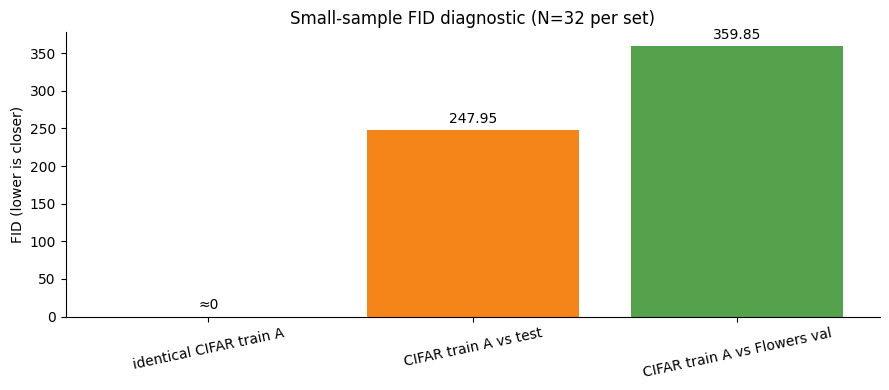

In [10]:
# Purpose: Compare the three FID results in a table and on one scale.
# Keep this order: control, same dataset, and different dataset.
fid_results = [fid_control, fid_cifar_splits, fid_cross_dataset]

# The table shows signed values. This includes numerical error near zero.
print(f"{'comparison':34s} {'FID':>12s} {'seconds':>10s}")
print("-" * 58)
for result in fid_results:
    print(
        f"{result['comparison']:34s} "
        f"{result['fid']:12.4f} {result['seconds']:10.2f}"
    )

# Get the figure values from the result records.
fig, axis = plt.subplots(figsize=(9, 4))
names = [result["comparison"] for result in fid_results]
raw_values = [result["fid"] for result in fid_results]
# FID cannot be negative in theory. Set only negative display error to zero.
plot_values = [max(0.0, value) for value in raw_values]
# Use an approximately-zero label for very small values. Keep full precision in the table.
value_labels = [
    "≈0" if abs(value) < 1e-3 else f"{value:.2f}" for value in raw_values
]
bars = axis.bar(
    names, plot_values, color=["#4C78A8", "#F58518", "#54A24B"]
)
# Put each value on its bar. The reader does not need to estimate the value.
axis.bar_label(bars, labels=value_labels, padding=3)
axis.set_ylabel("FID (lower is closer)")
axis.set_title(f"Small-sample FID diagnostic (N={N_FID} per set)")
axis.tick_params(axis="x", labelrotation=12)
axis.spines[["top", "right"]].set_visible(False)  # Remove lines that do not show data.
plt.tight_layout()
plt.show()


## 6. Interpretation

Use the three FID values only as diagnostic results. Do not use them as absolute quality scores.

1. The identical-input result tests the implementation. A value near zero shows that identical tensors produce identical feature statistics. Floating-point error can make this result slightly negative. Treat this value as zero.
2. The CIFAR train and CIFAR test result includes finite-sample variation. It can also include split differences. These effects can produce a large FID when each set has only 32 images.
3. The CIFAR and Flowers result measures a visible domain difference. A higher value agrees with this difference. The exact value is unstable for this sample size.

For paper results, use one fixed protocol for all generated and reference sets. Use more samples. Report the sample count. FID and nearest-neighbor metrics measure different properties. FID does not replace `d1`, `d2`, `r`, or `f_mem`.


## Exercise: distinguish split effects from dataset effects

First, predict whether two disjoint subsets from the **same CIFAR training split** have lower FID than train versus test. Then, set `RUN_EXERCISE = True`. If the result does not agree with your prediction, do not infer a split difference. At `N=32`, random variation can control the order.


In [11]:
# Purpose: Compare two disjoint samples from the same CIFAR split when requested.
RUN_EXERCISE = False  # Set this value to True to calculate one more FID value.

if RUN_EXERCISE:
    # A and B contain separate indices from one seeded train permutation.
    fid_same_split = measure_fid(
        "CIFAR train A vs train B", cifar_a, cifar_b
    )
    print(fid_same_split)
    # Compare this result with the train and test result. A small N can change the expected order.
    print(
        "Difference from train-vs-test: "
        f"{fid_same_split['fid'] - fid_cifar_splits['fid']:+.4f}"
    )
else:
    # Do not calculate the fourth value in the default procedure.
    print("Set RUN_EXERCISE = True to run one additional real FID comparison.")


Set RUN_EXERCISE = True to run one additional real FID comparison.


## Pitfalls and extensions

- **Small samples:** FID has finite-sample bias. Increase `N_FID`. Repeat the calculation with deterministic subsets. Estimate uncertainty before you make scientific conclusions.
- **Protocol changes:** Do not compare FID values when the feature extractor, image range, resize operation, or sample count changes.
- **Data overlap:** Use an identical-input control only to test the implementation. Do not use it as an evaluation reference. Paper runs must use saved, disjoint train and held-out artifacts.
- **Feature domain:** ImageNet-trained Inception features can represent some scientific image domains incorrectly. Interpret FID in relation to the feature space.
- **Memorization:** A model can have a good FID value and copy train samples. Measure distribution quality and memorization separately.

For the next experiment, replace `cifar_a` with samples from one saved checkpoint. Keep the same held-out reference tensor, preprocess, sample count, and feature extractor across `x`, `eps`, and `v`.


## Summary

This notebook showed the exact image tensors. It used the real torch-fidelity adapter. It tested the zero-distance control. It compared feature distributions. FID gives a valid comparison only when the input artifact, preprocess, feature extractor, and sample-count protocol are constant.
